# Calibration

## Importing packages

In [1]:
# Data handling and manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Statistical modeling and optimization
import statsmodels.api as sm
import optbinning as optb
from scipy.stats import chi2, binom

# Progress bar utility
from tqdm import tqdm

# Metrics
from sklearn.metrics import roc_auc_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Serialization and deserialization
import pickle

## Loading data

In [2]:
cali_data = pd.read_csv("Data/pd_modelling.csv")

## Loading model

In [3]:
with open("Pickle/binning_var.pkl", "rb") as f:
    binning = pickle.load(f)

In [4]:
with open("Pickle/model.pkl", "rb") as f:
    model = pickle.load(f)

## Calculating PD and WoE values

In [5]:
woe = []

for var in binning.keys():
    woe.append(pd.Series(binning[var].transform(cali_data[var], metric = "woe"), index=cali_data.index, name="WoE_" + var))

cali_data_woe = pd.concat([cali_data] + woe, axis=1)

In [6]:
vars = model.model.exog_names
cali_data_woe["const"] = 1

cali_data_woe["uncalibrated_pd"] = model.predict(cali_data_woe[vars])

C:\Users\niels\AppData\Local\Temp\ipykernel_23412\515790858.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cali_data_woe["const"] = 1
C:\Users\niels\AppData\Local\Temp\ipykernel_23412\515790858.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cali_data_woe["uncalibrated_pd"] = model.predict(cali_data_woe[vars])


## Calculating LRA DR

In [7]:
dr = cali_data_woe.groupby("quarter")[["default_12m", "uncalibrated_pd"]].mean()

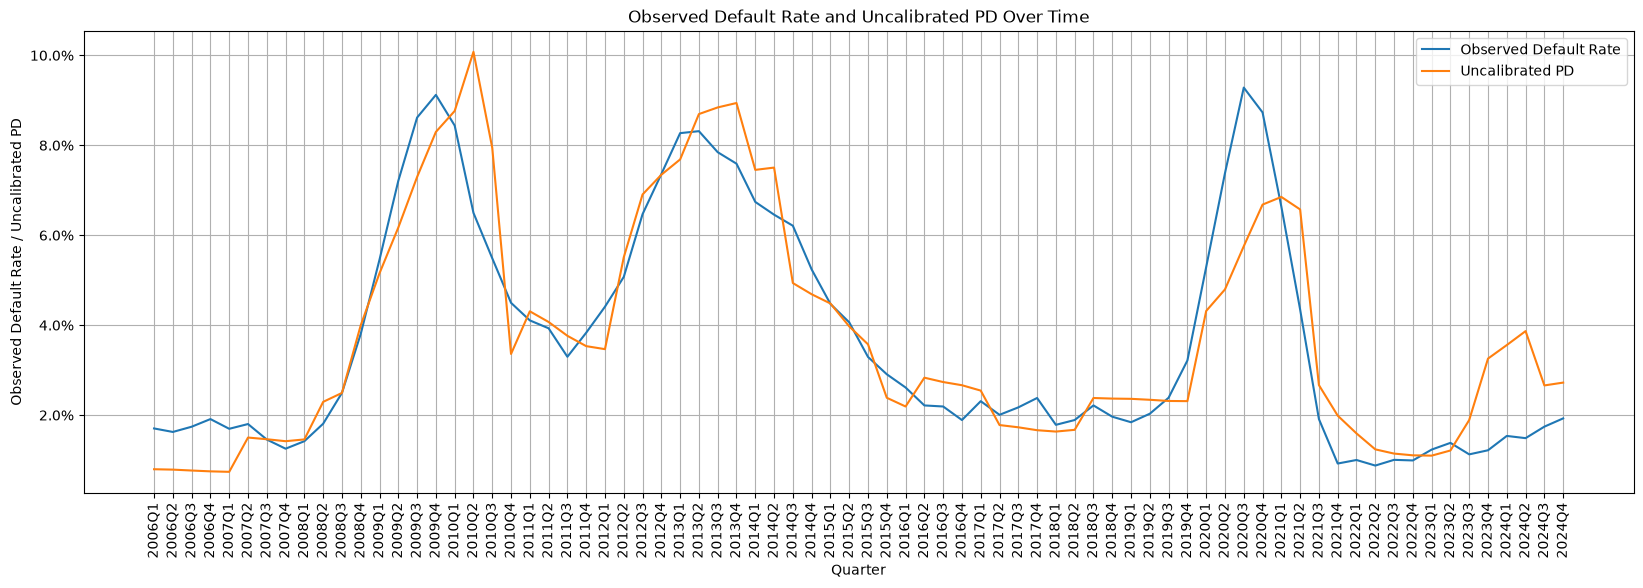

In [8]:
plt.figure(figsize=(20, 6))
plt.plot(dr.index, dr["default_12m"], label="Observed Default Rate")
plt.plot(dr.index, dr["uncalibrated_pd"], label="Uncalibrated PD")
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / Uncalibrated PD")
plt.title("Observed Default Rate and Uncalibrated PD Over Time")
plt.xticks(rotation=90)
plt.grid(True)
plt.legend(loc = 'best')
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax = 1, decimals = 1))
plt.show()

In [9]:
lra_dr = dr["default_12m"].mean()

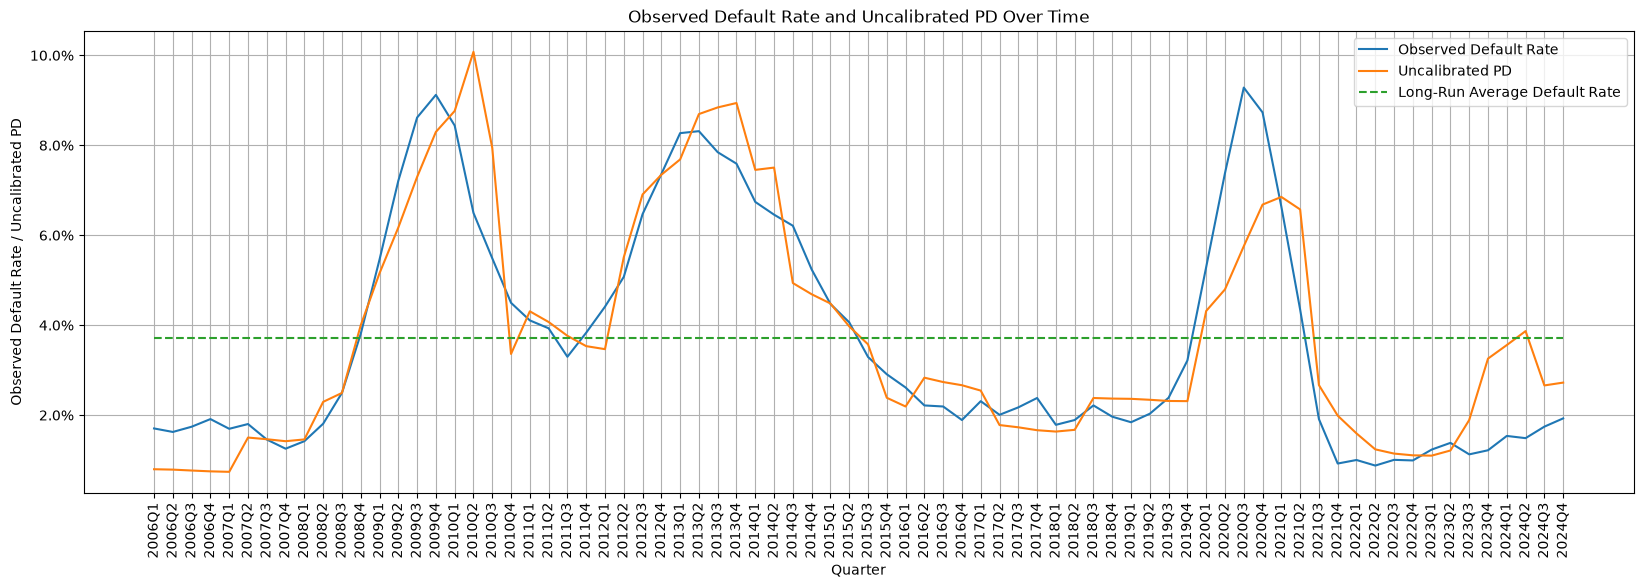

In [10]:
plt.figure(figsize=(20, 6))
plt.plot(dr.index, dr["default_12m"], label="Observed Default Rate")
plt.plot(dr.index, dr["uncalibrated_pd"], label="Uncalibrated PD")
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / Uncalibrated PD")
plt.title("Observed Default Rate and Uncalibrated PD Over Time")
plt.xticks(rotation=90)
plt.plot(dr.index, [lra_dr]*len(dr.index), label="Long-Run Average Default Rate", linestyle="--")
plt.grid(True)
plt.legend(loc = 'best')
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax = 1, decimals = 1))
plt.show()

In [11]:
def adjustment_score(pds, target):
    logodds = np.log(pds / (1 - pds))
    
    def sigmoid(x):
        return 1 / (1 + np.exp(-x))

    def f(k):
        return np.mean(sigmoid(logodds + k)) - target
    
    def derivative(k):
        s = sigmoid(logodds + k)
        return np.mean(s * (1 - s))

    # Use Newton-Raphson method to find the root of f(k)
    k = 0.0
    for _ in range(100):
        fk = f(k)
        if abs(fk) < 1e-8:
            break
        k -= fk / derivative(k)
    return k


In [23]:
adjustment_quarter = (cali_data_woe["quarter"] == "2024Q4")  # Example quarter, replace with the desired one

k = adjustment_score(cali_data_woe[adjustment_quarter]["uncalibrated_pd"], target = lra_dr)

In [24]:
cali_data_woe["pd"] = 1 / (1 + np.exp(-(np.log(cali_data_woe["uncalibrated_pd"] / (1 - cali_data_woe["uncalibrated_pd"])) + k)))

In [25]:
edr = cali_data_woe.groupby("quarter")["pd"].mean()

## Adjustment period

In [32]:
adjustment_period = (cali_data_woe["quarter"] >= "2021Q4")  # Example period, replace with the desired one

In [33]:
adjustment_data = cali_data_woe[adjustment_period].copy()

## Curve calibration

In [48]:
cutter = optb.OptimalBinning(name = "uncalibrated_pd", min_bin_size=0.005, monotonic_trend="ascending")
cutter.fit(adjustment_data["uncalibrated_pd"], adjustment_data["default_12m"])

,name,'uncalibrated_pd'
,min_bin_size,0.005
,monotonic_trend,'ascending'
,dtype,'numerical'
,prebinning_method,'cart'
,solver,'cp'
,divergence,'iv'
,max_n_prebins,20
,min_prebin_size,0.05
,min_n_bins,None
,max_n_bins,None


In [49]:
cutter.binning_table.build()

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.01)",2160,0.121280,2147,13,0.006019,0.748176,0.048119,5.878386e-03
1,"[0.01, 0.01)",1968,0.110500,1956,12,0.006098,0.735049,0.042558,5.203103e-03
2,"[0.01, 0.02)",8101,0.454857,8001,100,0.012344,0.02345,0.000247,3.091173e-05
3,"[0.02, 0.04)",2865,0.160865,2829,36,0.012565,0.005458,0.000005,5.975309e-07
4,"[0.04, 0.05)",1811,0.101684,1773,38,0.020983,-0.515859,0.035112,4.340923e-03
5,"[0.05, inf)",905,0.050814,879,26,0.028729,-0.838013,0.054948,6.674360e-03
6,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000e+00
7,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000e+00
Totals,,17810,1.000000,17585,225,0.012633,,0.180989,2.212828e-02


In [51]:
adjustment_data["bin"] = cutter.transform(adjustment_data["uncalibrated_pd"], metric="bins")

In [53]:
grouping = adjustment_data.groupby("bin").agg({
    "uncalibrated_pd": "mean",
    "default_12m": "mean"
})

In [55]:
grouping["uncalibrated_score"] = -np.log(grouping["uncalibrated_pd"]/(1-grouping["uncalibrated_pd"]))
grouping["central_score"] = -np.log(grouping["default_12m"]/(1-grouping["default_12m"]))

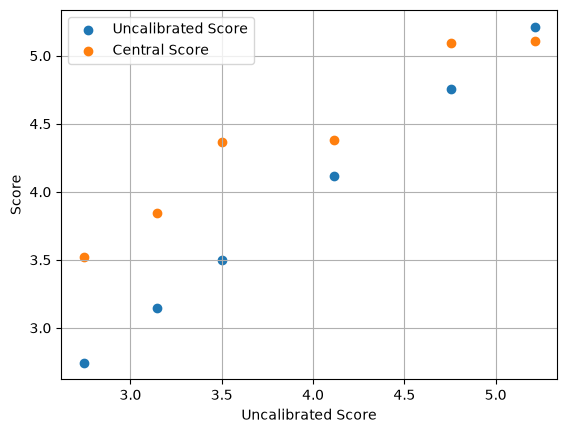

In [59]:
plt.scatter(grouping["uncalibrated_score"], grouping["uncalibrated_score"], label="Uncalibrated Score")
plt.scatter(grouping["uncalibrated_score"], grouping["central_score"], label="Central Score")
plt.xlabel("Uncalibrated Score")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

In [79]:
kurve = sm.OLS(endog = grouping["central_score"], exog = sm.add_constant(grouping["uncalibrated_score"])).fit(disp=0)
print(kurve.summary())

                            OLS Regression Results                            
Dep. Variable:          central_score   R-squared:                       0.935
Model:                            OLS   Adj. R-squared:                  0.919
Method:                 Least Squares   F-statistic:                     57.85
Date:                 ma, 19 okt 2026   Prob (F-statistic):            0.00160
Time:                        01:17:39   Log-Likelihood:                 2.9015
No. Observations:                   6   AIC:                            -1.803
Df Residuals:                       4   BIC:                            -2.220
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  1.8419      0

c:\Users\niels\Documents\PD-modelling\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 6 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


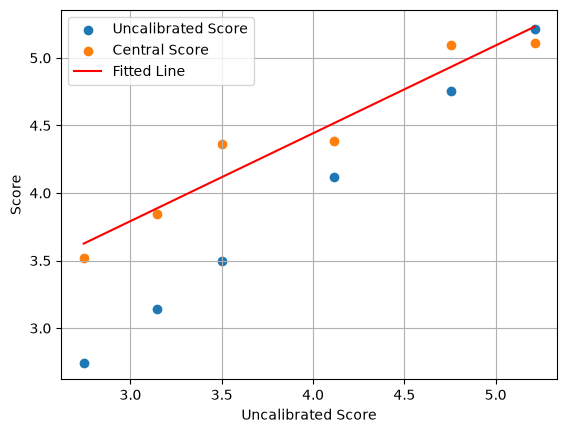

In [81]:
plt.scatter(grouping["uncalibrated_score"], grouping["uncalibrated_score"], label="Uncalibrated Score")
plt.scatter(grouping["uncalibrated_score"], grouping["central_score"], label="Central Score")
plt.plot(grouping["uncalibrated_score"], kurve.fittedvalues, color="red", label="Fitted Line")
plt.xlabel("Uncalibrated Score")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

In [82]:
cali_data_woe["uncalibrated_score"] = -np.log(cali_data_woe["uncalibrated_pd"]/(1-cali_data_woe["uncalibrated_pd"]))

In [83]:
cali_data_woe["curved_score"] = kurve.predict(sm.add_constant(cali_data_woe["uncalibrated_score"]))

C:\Users\niels\AppData\Local\Temp\ipykernel_23412\3611040671.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cali_data_woe["curved_score"] = kurve.predict(sm.add_constant(cali_data_woe["uncalibrated_score"]))


In [88]:
cali_data_woe["curved_pd"] = 1 / (1 + np.exp(cali_data_woe["curved_score"]))

In [104]:
k = adjustment_score(cali_data_woe[adjustment_period]["curved_pd"], lra_dr)

In [105]:
cali_data_woe["adjusted_curved_pd"] = 1 / (1 + np.exp((cali_data_woe["curved_score"] - k)))

In [106]:
edr = cali_data_woe.groupby("quarter")["adjusted_curved_pd"].mean()

In [107]:
lra_dr

np.float64(0.037249380279295294)

In [108]:
np.mean(cali_data_woe[adjustment_period]["adjusted_curved_pd"])

np.float64(0.03724938432800849)

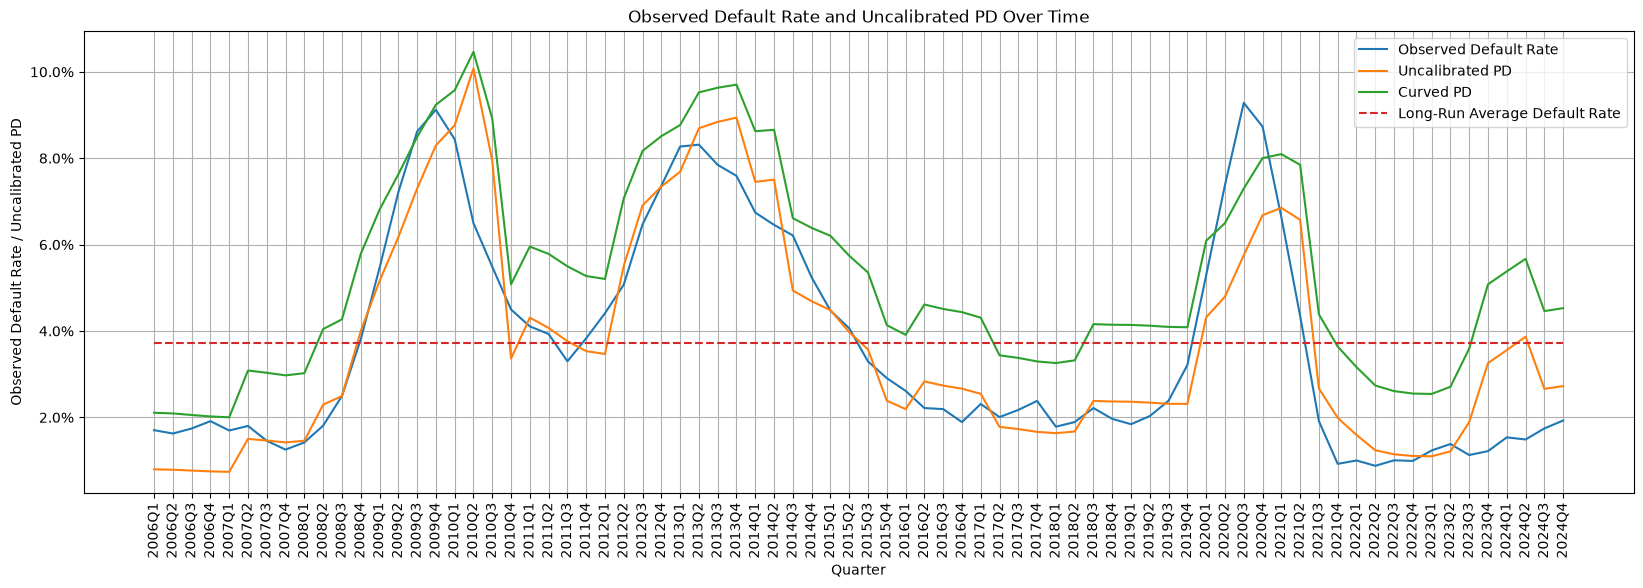

In [109]:
plt.figure(figsize=(20, 6))
plt.plot(dr.index, dr["default_12m"], label="Observed Default Rate")
plt.plot(dr.index, dr["uncalibrated_pd"], label="Uncalibrated PD")
plt.plot(edr.index, edr, label="Curved PD")
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / Uncalibrated PD")
plt.title("Observed Default Rate and Uncalibrated PD Over Time")
plt.xticks(rotation=90)
plt.plot(dr.index, [lra_dr]*len(dr.index), label="Long-Run Average Default Rate", linestyle="--")
plt.grid(True)
plt.legend(loc = 'best')
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax = 1, decimals = 1))
plt.show()